# J4 · Photodynamics: NbodyGradient + Pizzetti

**Level:** advanced · **Prerequisites:** [J1](J1_quickstart.ipynb), [J2](J2_gradients.ipynb)
· **Run time:** ~3 min

**Covers:** the derivative of every sample of a photodynamical light curve with respect to
every initial orbital element and mass, by joining NbodyGradient.jl and Pizzetti with the
chain rule, and a check against finite differences of the whole pipeline.

A two-planet system near the 2:1 resonance shows transit-timing variations (TTVs).
[NbodyGradient.jl](https://github.com/ericagol/NbodyGradient.jl) (Agol, Hernandez & Langford
2021) integrates the N-body problem and returns, for every transit, the mid-transit time
$t_c$, the sky velocity $v$ and the impact parameter $b$, together with their derivatives with
respect to the initial conditions. Around each transit the sky path is a straight line,

$$z(t) = \frac{\sqrt{b^2 + v^2\,(t - t_c)^2}}{R_\star},$$

and Pizzetti computes the flux $F(z)$ and its exact derivative $\partial F/\partial z$
(paper, Sect. 3.2). The chain rule gives the derivative of every light-curve sample with
respect to every initial condition $x$,

$$\frac{\mathrm{d}F_i}{\mathrm{d}x} = \frac{\partial F}{\partial z}\left(
\frac{\partial z}{\partial t_c}\frac{\mathrm{d}t_c}{\mathrm{d}x} +
\frac{\partial z}{\partial v}\frac{\mathrm{d}v}{\mathrm{d}x} +
\frac{\partial z}{\partial b^2}\frac{\mathrm{d}b^2}{\mathrm{d}x}\right),$$

which is the gradient of a photodynamical likelihood.

In [1]:
using Pizzetti, NbodyGradient, ForwardDiff, Plots, LinearAlgebra
include("theme.jl")

const RSUN_AU = 0.00465047
const Rstar = 1.0 * RSUN_AU
law = Power2(0.6, 0.6)
radius_ratio = [0.03, 0.06];                        # planets b and c

## 1. Initial conditions

A Sun-like star, a sub-Neptune (b) and a Saturn-mass planet (c) near the 2:1 resonance.
Masses in solar masses, periods and times in days, angles in radians; the columns are
$(m, P, t_0, e\cos\omega, e\sin\omega, I, \Omega)$.

          m        P       t0    ecosω   esinω   I            Ω

In [2]:
elements = [1.0      0.0     0.0   0.0     0.0     0.0          0.0;
            3.0e-5   10.0    2.0   0.01    0.005   π/2 - 0.010  0.0;
            3.0e-4   20.55   5.0   0.02   -0.01    π/2 - 0.005  0.0]
tmax = 400.0

function transits(elements; grad = true)
    ic = ElementsIC(0.0, 3, elements)
    s = State(ic)
    tp = TransitParameters(tmax, ic)
    Integrator(ahl21!, 10.0 / 40, tmax)(s, tp; grad = grad)
    return tp
end
tp = transits(elements);

## 2. The light curve

Samples at 2-min cadence within $\pm 0.3$ d of every transit; for each sample and planet, the
nearest transit gives $t_c$, $v$ and $b^2$, and so $z$.

In [3]:
function windows(tp; half = 0.3, cadence = 2 / 1440)
    ts = Float64[]
    for j in 2:3, k in 1:tp.count[j]
        tc = tp.ttbv[1, j, k]
        0 < tc < tmax || continue
        append!(ts, tc-half:cadence:tc+half)
    end
    sort!(unique!(ts))
end
t = windows(tp)
table(["", ""], [("light-curve samples", length(t)), ("transits of b", tp.count[2]), ("transits of c", tp.count[3])])

,
light-curve samples,25976
transits of b,40
transits of c,20


In [4]:
function nearest(tp, j, ti)
    best, kb = Inf, 0
    for k in 1:tp.count[j]
        d = abs(ti - tp.ttbv[1, j, k])
        d < best && ((best, kb) = (d, k))
    end
    kb
end
zsky(tc, v, b2, ti) = sqrt(b2 + v^2 * (ti - tc)^2) / Rstar

function lightcurve(tp, t, ps, law)
    F = ones(length(t))
    for (i, ti) in enumerate(t), j in 2:3
        k = nearest(tp, j, ti)
        z = zsky(tp.ttbv[1, j, k], tp.ttbv[2, j, k], tp.ttbv[3, j, k], ti)
        F[i] += occult(z, ps[j-1], law) - 1
    end
    F
end
F = lightcurve(tp, t, radius_ratio, law);

## 3. The Jacobian: every sample against every initial condition

`flux_gradient` returns $\partial F/\partial z$ in closed form; the derivatives of $z$ with
respect to $(t_c, v, b^2)$ come from ForwardDiff, those of $(t_c, v, b^2)$ with respect to the
initial conditions from NbodyGradient (`tp.dtbvdelements`).

In [5]:
function lightcurve_jacobian(tp, t, ps, law)
    J = zeros(length(t), 7, 3)                      # sample × element × body
    for (i, ti) in enumerate(t), j in 2:3
        k = nearest(tp, j, ti)
        tc, v, b2 = tp.ttbv[1, j, k], tp.ttbv[2, j, k], tp.ttbv[3, j, k]
        z = zsky(tc, v, b2, ti)
        z >= 1 + ps[j-1] && continue
        _, dFdz, _, _ = flux_gradient(z, ps[j-1], law)
        dz = ForwardDiff.gradient(q -> zsky(q[1], q[2], q[3], ti), [tc, v, b2])
        for l in 1:7, body in 1:3
            J[i, l, body] += dFdz * (dz[1] * tp.dtbvdelements[1, j, k, l, body] +
                                     dz[2] * tp.dtbvdelements[2, j, k, l, body] +
                                     dz[3] * tp.dtbvdelements[3, j, k, l, body])
        end
    end
    J
end
lightcurve_jacobian(tp, t, radius_ratio, law)                  # compile
tJ = @elapsed J = lightcurve_jacobian(tp, t, radius_ratio, law)
tF = @elapsed lightcurve(tp, t, radius_ratio, law)
table(["", "time"], [("light curve", @sprintf("%.1f ms", 1e3tF)),
                     ("Jacobian, $(length(t)) samples × 21 initial conditions", @sprintf("%.1f ms", 1e3tJ))])

,time
light curve,379.5 ms
"Jacobian, 25976 samples × 21 initial conditions",1406.2 ms


## 4. Check against finite differences of the whole pipeline

Each initial condition is perturbed by $\pm h$, the N-body integration and the light curve are
recomputed, and the central difference is compared with the corresponding column of the
Jacobian. (The columns of the elements matrix are $(m, P, t_0, e\cos\omega, e\sin\omega, I,
\Omega)$; NbodyGradient orders its derivatives as $(P, t_0, e\cos\omega, e\sin\omega, I,
\Omega, m)$.)

In [6]:
slot(col) = col == 1 ? 7 : col - 1
function fd_column(col, body; h)
    e1 = copy(elements); e1[body, col] += h
    e2 = copy(elements); e2[body, col] -= h
    F1 = lightcurve(transits(e1; grad = false), t, radius_ratio, law)
    F2 = lightcurve(transits(e2; grad = false), t, radius_ratio, law)
    (F1 .- F2) ./ 2h
end
rows = map((("m", 1, 3, 1e-9), ("P", 2, 3, 1e-6), ("t₀", 3, 2, 1e-6), ("e cos ω", 4, 3, 1e-6), ("I", 6, 2, 1e-7))) do (name, col, body, h)
    fd = fd_column(col, body; h = h)
    an = J[:, slot(col), body]
    (name, ("star", "b", "c")[body], sci(h, 1), sci(maximum(abs, an), 4), sci(maximum(abs, an .- fd) / maximum(abs, an)))
end
table(["initial condition", "body", "h", "max abs dF/dx (chain rule)", "max abs difference / max abs dF/dx"], rows)

initial condition,body,h,max abs dF/dx (chain rule),max abs difference / max abs dF/dx
m,c,1e-09,1.669e+02,7.6e-06
P,c,1e-06,5.683e+00,1.5e-05
t₀,b,1e-06,1.650e-01,1.0e-05
e cos ω,c,1e-06,3.260e-01,9.1e-06
I,b,1e-07,5.615e-02,1.0e-05


The finite differences straddle the contact points, where the flux is not smooth (it has a
term $\propto \delta^{\gamma + 3/2}$ at second contact, paper Sect. 6.1), which limits their
agreement to $\sim 10^{-5}$; the chain rule has no such limitation. (For the mass of planet c
the step must be small, $10^{-9}\,M_\odot$: the TTVs depend nonlinearly on it, and the
difference with the chain rule shrinks as $h^2$, from $2 \times 10^{-2}$ at $h = 10^{-7}$.)

## 5. Transit-timing variations

The transit times minus a linear ephemeris, for both planets:

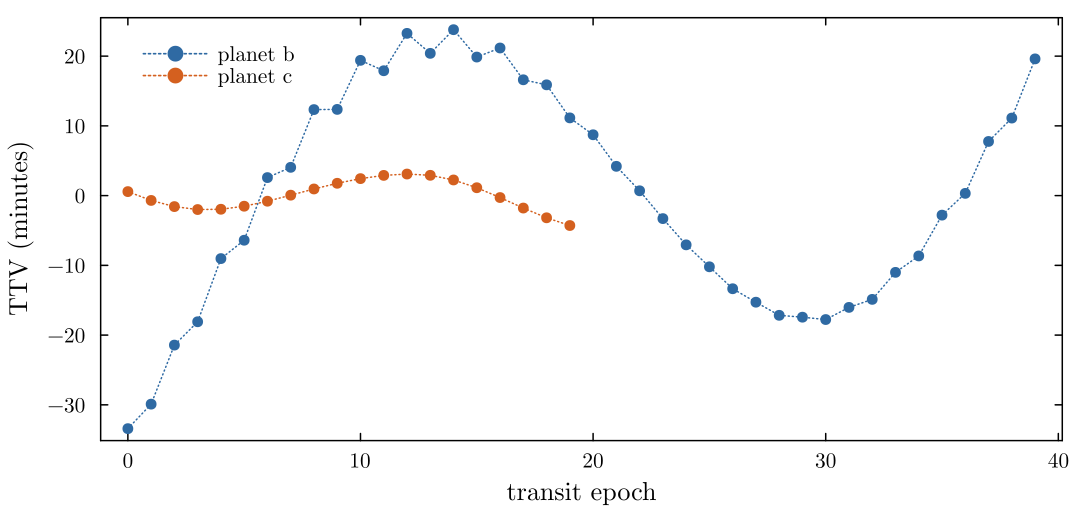

In [7]:
plt1 = plot(xlabel = "transit epoch", ylabel = "TTV (minutes)", size = (720, 340), legend = :topleft)
for (j, name, col) in ((2, "planet b", COLORS.series), (3, "planet c", COLORS.limb))
    n = tp.count[j]
    tc = [tp.ttbv[1, j, k] for k in 1:n if 0 < tp.ttbv[1, j, k] < tmax]
    e = 0:length(tc)-1
    lin = hcat(ones(length(e)), e) \ tc
    plot!(plt1, e, 1440 .* (tc .- (lin[1] .+ lin[2] .* e)), label = name, color = col, lw = 1, ls = :dot,
          marker = :circle, ms = 4, msw = 0)
end
plt1

## 6. The sensitivity of one transit to the mass of planet c

A column of the Jacobian, $\mathrm{d}F/\mathrm{d}m_c$, for the eighth transit of planet b:
the mass of the outer planet shifts the transit in time through the TTV, so the light curve
changes antisymmetrically at ingress and egress.

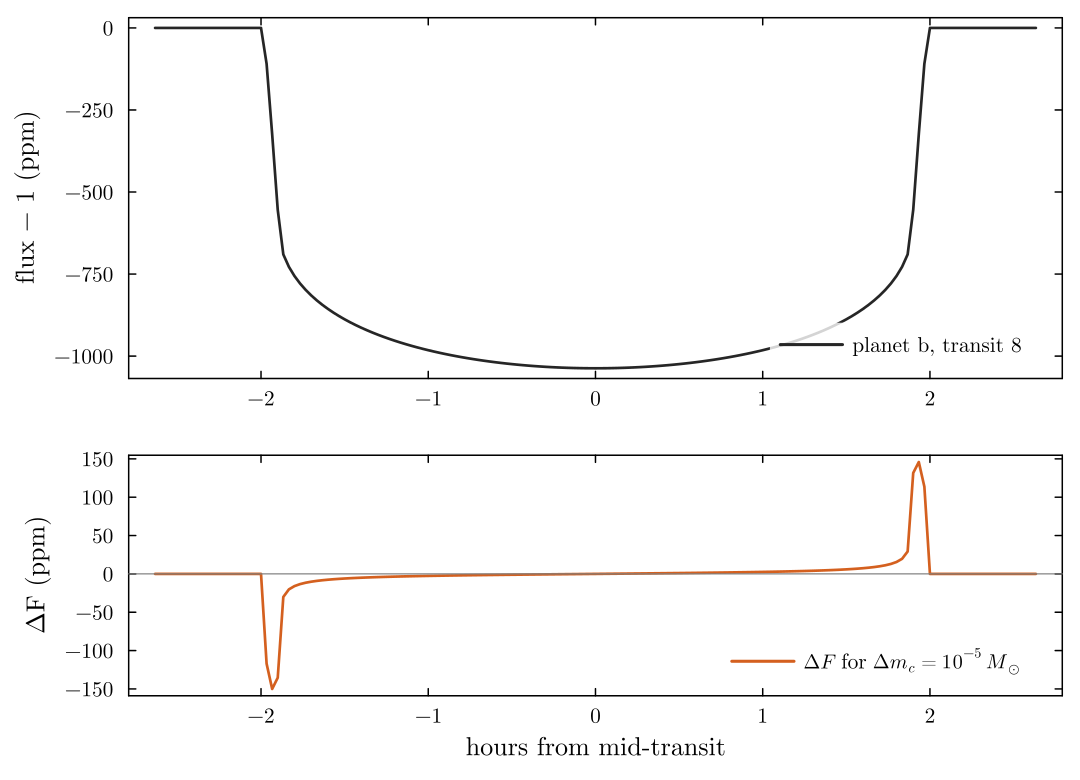

In [8]:
k = 8
tcb = tp.ttbv[1, 2, k]
sel = abs.(t .- tcb) .< 0.11
plt2 = plot(layout = grid(2, 1, heights = [0.6, 0.4]), size = (720, 520), link = :x)
plot!(plt2[1], 24 .* (t[sel] .- tcb), 1e6 .* (F[sel] .- 1), color = COLORS.ink, label = "planet b, transit $k",
      ylabel = "flux − 1 (ppm)", legend = :bottomright)
plot!(plt2[2], 24 .* (t[sel] .- tcb), 1e6 .* J[sel, slot(1), 3] .* 1e-5, color = COLORS.limb,
      label = L"$\Delta F$ for $\Delta m_c = 10^{-5}\,M_\odot$", xlabel = "hours from mid-transit",
      ylabel = "ΔF (ppm)", legend = :bottomright)
hline!(plt2[2], [0], color = :gray50, lw = 0.8, label = "")
plt2

## What you learned

- NbodyGradient supplies transit times, sky velocities and impact parameters with their
  derivatives; Pizzetti supplies $F$ and $\partial F/\partial z$; the chain rule joins them;
- this gives the gradient of a photodynamical light curve with respect to every initial
  condition and mass, ready for gradient-based fitting or Hamiltonian Monte Carlo.

**Next:** [J5 · Interoperability](J5_interoperability.ipynb).